In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import accuracy_score  
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import warnings, random
warnings.filterwarnings("ignore")

seed = 1
random.seed(seed)
np.random.seed(seed)

df = pd.read_csv('SE5.csv')
df['Time'] = pd.to_datetime(df['Time'])
df = df.sort_values(by='Time', ascending=True)

train_val_df = df[df["Time"] < "2024-01-01"]
test_df = df[df["Time"] >= "2024-01-01"]

forward_test_df = pd.read_csv('SE5-2.csv')
forward_test_df['Time'] = pd.to_datetime(forward_test_df['Time'])
forward_test_df = forward_test_df.sort_values(by='Time', ascending=True)
macro_level_features = np.loadtxt('macro_level_features.txt', dtype='O')

print(f"Train/Validation data shape: {train_val_df.shape}")
print(f"Test data shape: {test_df.shape}")
print(f"Forward Test data shape: {forward_test_df.shape}")

Train/Validation data shape: (40884, 717)
Test data shape: (2313, 717)
Forward Test data shape: (1182, 717)


In [2]:
pca_components = .85

def preprocess_data_for_clustering(df):
    X = df.copy()
    X.set_index('Time', inplace=True)
    X = X.sort_index()
    X = X[macro_level_features]
    feature_scaler = StandardScaler()
    X_scaled = feature_scaler.fit_transform(X)
    pca = PCA(n_components=pca_components, random_state=1)
    X_pca = pca.fit_transform(X_scaled)
    return X_pca, feature_scaler, pca

X, feature_scaler, pca = preprocess_data_for_clustering(train_val_df)

In [41]:
# plt.figure(figsize=(8, 4))
# plt.plot(np.cumsum(pca.explained_variance_ratio_) * 100)
# plt.axhline(y=95, color='r', linestyle='--')
# plt.title('Cumulative Explained Variance by PCA Components')
# plt.xlabel('Number of Components')
# plt.ylabel('Explained Variance (%)')
# plt.grid(True)
# plt.show()

In [42]:
# regimes_range = range(1, 7)
# aic_scores = list()
# bic_scores = list()

# for regime_count in regimes_range:
#     hmm_model = GaussianHMM(n_components=regime_count, covariance_type="diag", n_iter=100, random_state=seed)
#     hmm_model.fit(X)

#     aic = hmm_model.aic(X)
#     bic = hmm_model.bic(X)

#     aic_scores.append(aic)
#     bic_scores.append(bic)

# plt.plot(regimes_range, bic_scores, label='BIC', marker='o')
# plt.plot(regimes_range, aic_scores, label='AIC', marker='o')
# plt.xlabel('Number of States')
# plt.ylabel('Score')
# plt.legend()
# plt.show()
# np.array([aic_scores, bic_scores]).round(2)

(32500, 48) (8384, 48)


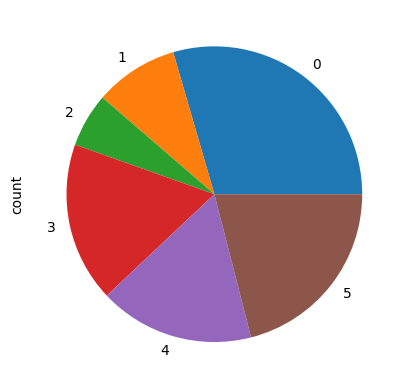

[12059  3751  2410  7140  6937  8587]


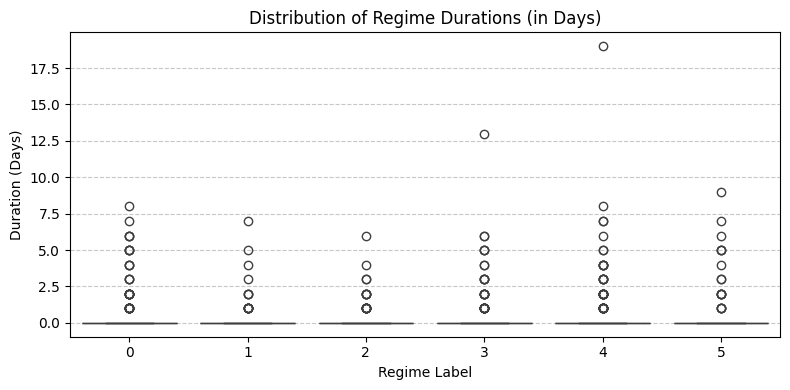

In [3]:
# Predicting Regime labels based on 80%-20% split train/valid

train_dfc = X[:32500] # ~80%, 20%
valid_dfc = X[32500:]
print(train_dfc.shape, valid_dfc.shape)

hmm_model = GaussianHMM(n_components=6, covariance_type='full', n_iter=100, random_state=seed)
hmm_model.fit(train_dfc)
train_labels = hmm_model.predict(train_dfc)
valid_labels = hmm_model.predict(valid_dfc)
train_val_df['Regime'] = np.concatenate([train_labels, valid_labels])
train_val_df['Regime'].value_counts().sort_index().plot(kind='pie')
plt.show()
print(train_val_df['Regime'].value_counts().sort_index().values)

train_val_df['Regime_Shift'] = (train_val_df['Regime'] != train_val_df['Regime'].shift(1)).cumsum()
regime_durations = train_val_df.groupby(['Regime_Shift', 'Regime'])['Time'].apply(lambda x: (x.max() - x.min()).days).reset_index(name='Duration_Days')

plt.figure(figsize=(8, 4))
sns.boxplot(x='Regime', y='Duration_Days', data=regime_durations)
plt.title('Distribution of Regime Durations (in Days)')
plt.xlabel('Regime Label')
plt.ylabel('Duration (Days)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [28]:
# Assuming train_val_df['Regime'] contains the raw HMM predictions
window_size = 10
train_val_df['Smoothed_Regime'] = train_val_df['Regime'].rolling(window=window_size, center=True).apply(lambda x: pd.Series(x).mode()[0], raw=False)
# Handle NaN values at the start/end due to rolling window
train_val_df['Smoothed_Regime'].fillna(method='ffill', inplace=True)
train_val_df['Smoothed_Regime'].fillna(method='bfill', inplace=True)
train_val_df['Smoothed_Regime'] = train_val_df['Smoothed_Regime'].astype(int)

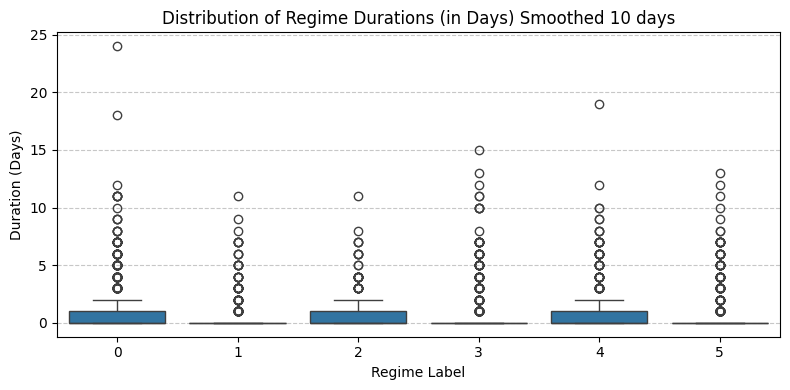

In [32]:
train_val_df['Regime_Shift_smoothed'] = (train_val_df['Smoothed_Regime'] != train_val_df['Smoothed_Regime'].shift(1)).cumsum()
regime_durations_smoothed = train_val_df.groupby(['Regime_Shift_smoothed', 'Smoothed_Regime'])['Time'].apply(lambda x: (x.max() - x.min()).days).reset_index(name='Duration_Days')
plt.figure(figsize=(8, 4))
sns.boxplot(x='Smoothed_Regime', y='Duration_Days', data=regime_durations_smoothed)
plt.title('Distribution of Regime Durations (in Days) Smoothed 10 days')
plt.xlabel('Regime Label')
plt.ylabel('Duration (Days)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [30]:
train_labels = train_val_df['Smoothed_Regime'].loc[:32499].values
valid_labels = train_val_df['Smoothed_Regime'].loc[32500:].values

In [31]:
# X = train_dfc + valid_dfc
y = np.concatenate([train_labels, valid_labels])

x_tr, y_tr = train_dfc, train_labels
x_va, y_va = valid_dfc, valid_labels

regime_model = lgb.LGBMClassifier(objective='multiclass', class_weight='balanced', num_class=len(np.unique(y)), random_state=seed,learning_rate=0.05,n_estimators=1000,n_jobs=-1,verbose=-1)
regime_model.fit(x_tr, y_tr, eval_set=[(x_va, y_va)], eval_metric="multi_logloss",callbacks=[lgb.early_stopping(stopping_rounds=20, verbose=True)])

pred_regime_valid = regime_model.predict(x_va)
print('Valid Accuracy:', accuracy_score(y_va, pred_regime_valid))

tscv = TimeSeriesSplit(n_splits=5)
cv_scores = cross_val_score(regime_model, X, y, scoring="balanced_accuracy", cv=tscv)
print('Mean CV Score:', np.mean(cv_scores))


Training until validation scores don't improve for 20 rounds
Early stopping, best iteration is:
[247]	valid_0's multi_logloss: 0.778359
Valid Accuracy: 0.7439169847328244
Mean CV Score: 0.66895631278177


In [ ]:
# Predicting regime label using LGBM classifier and add it to the full data (before 2024)
train_val_df['Regime'] = regime_model.predict(X)

In [ ]:
plt.figure(figsize=(18, 5))
plt.scatter(x=train_val_df['Time'], y=train_val_df['Regime'], alpha=0.01)
plt.show()

Text(0.5, 1.0, 'Regime 5, 8587 samples, 21% of population')

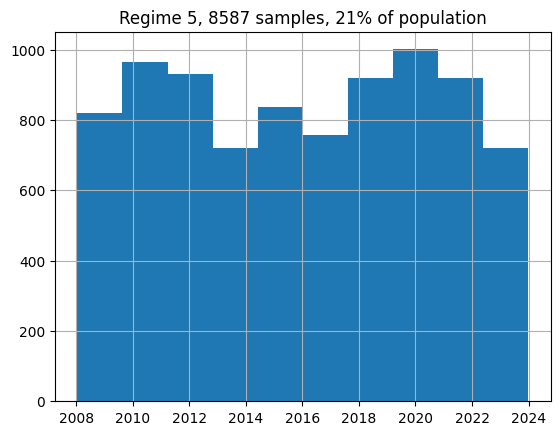

In [10]:
r = 5
train_val_df.loc[train_val_df['Regime']==r, 'Time'].hist()
n_samples = len(train_val_df.loc[train_val_df['Regime']==r, 'Time'])
n_ratio = (n_samples / train_val_df.shape[0]) * 100
plt.title(f'Regime {r}, {n_samples} samples, {n_ratio:.0f}% of population')

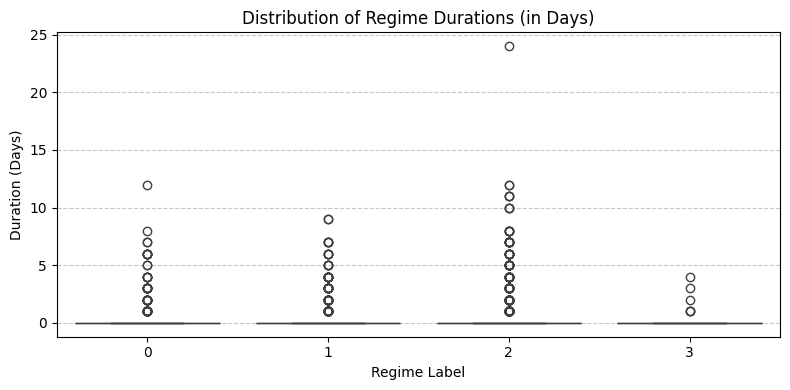

In [50]:
# Calculate the duration of each spell within a regime
import seaborn as sns

train_val_df['Regime_Shift'] = (train_val_df['Regime'] != train_val_df['Regime'].shift(1)).cumsum()
regime_durations = train_val_df.groupby(['Regime_Shift', 'Regime'])['Time'].apply(lambda x: (x.max() - x.min()).days).reset_index(name='Duration_Days')

plt.figure(figsize=(8, 4))
sns.boxplot(x='Regime', y='Duration_Days', data=regime_durations)
plt.title('Distribution of Regime Durations (in Days)')
plt.xlabel('Regime Label')
plt.ylabel('Duration (Days)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
# Predict regime labels on test data 2024 & adding labels
X_Test_2024,_,_ = preprocess_data_for_clustering(test_df)
test_df_regime_labels = hmm_model.predict(X_Test_2024)
test_df['Regime'] = test_df_regime_labels

In [ ]:
# Predict regime labels on test data 2025 & adding labels
X_Test_2025,_,_ = preprocess_data_for_clustering(forward_test_df)
forward_test_df_regime_labels = hmm_model.predict(X_Test_2025)
forward_test_df['Regime'] = forward_test_df_regime_labels

In [ ]:
# Extracting training data
regime_labels = train_val_df['Regime'].unique()
for regime in regime_labels:
    train_val_df[train_val_df['Regime']==regime].to_csv(f'subsets_hmm/hmm_subset_Regime{regime}.csv', index=False)
    test_df[test_df['Regime']==regime].to_csv(f'subsets_hmm/hmm_test_subset_Regime{regime}.csv', index=False)
    forward_test_df[forward_test_df['Regime']==regime].to_csv(f'subsets_hmm/hmm_forward_test_subset_Regime{regime}.csv', index=False)